# Denoising-Autoencoder Pretraining and Fine-Tuning

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score, confusion_matrix
import data_loading.v2_loader as v2

np.random.seed(42)
tf.random.set_seed(42)

Loading PADS 11-task pretraining cohort and 5-task primary classification cohort

In [2]:
pads_data, pads_meta = v2.load_v1_pads_data(results_dir=os.path.join("..", "results"))
all_win, all_meta = v2.load_v2_all_tasks_data(results_dir=os.path.join("..", "results"))
splits = v2.load_fold_splits(results_dir=os.path.join("..", "results"))

y_pads = pads_meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values
groups = pads_meta["subject_id"].values
unique_subs = pads_meta["subject_id"].unique()
sub_true = np.array([y_pads[groups == s][0] for s in unique_subs])
target_names = ["Normal", "Parkinsons-like", "ET-like"]

Xd_primary = pads_data - pads_data.mean(axis=1, keepdims=True)
Xd_all = all_win - all_win.mean(axis=1, keepdims=True)

print("Primary 5-task cohort shape:", pads_data.shape)
print("Multi-task pretraining pool shape:", all_win.shape)
print("Unique pretraining subjects:", all_meta["subject_id"].nunique())

Primary 5-task cohort shape: (25500, 300, 6)
Multi-task pretraining pool shape: (31892, 300, 6)
Unique pretraining subjects: 469


Defining the Denoising-Autoencoder (DAE) and corrupting transform (Gaussian noise + segment masking)

In [3]:
def build_dae(input_shape=(300, 6)):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
    x = layers.Dropout(0.2)(x)
    emb = layers.Bidirectional(layers.LSTM(16))(x)
    
    d = layers.Dense(37 * 32, activation="relu")(emb)
    d = layers.Reshape((37, 32))(d)
    d = layers.UpSampling1D(2)(d)
    d = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(d)
    d = layers.UpSampling1D(2)(d)
    d = layers.Conv1D(32, kernel_size=3, padding="same", activation="relu")(d)
    d = layers.UpSampling1D(2)(d)
    d = layers.ZeroPadding1D((2, 2))(d)
    out = layers.Conv1D(6, kernel_size=3, padding="same")(d)
    
    encoder = models.Model(inputs=inp, outputs=emb, name="dae_encoder")
    autoencoder = models.Model(inputs=inp, outputs=out, name="dae_autoencoder")
    autoencoder.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return encoder, autoencoder

def apply_dae_corruption(X, noise_sigma=0.1, mask_len=40, seed=42):
    rng = np.random.default_rng(seed)
    X_corr = X.copy()
    n, t, c = X.shape
    noise = rng.normal(0, noise_sigma, size=(n, t, c)).astype(np.float32)
    X_corr = X_corr + noise
    for i in range(n):
        start = rng.integers(0, t - mask_len)
        X_corr[i, start:start+mask_len, :] = 0.0
    return X_corr

Pretraining the DAE once per fold on all 11 tasks (strictly excluding test-fold subjects)

In [4]:
os.makedirs(os.path.join("..", "results", "models"), exist_ok=True)
sample_recon_orig = None
sample_recon_corr = None
sample_recon_pred = None

for fold in range(5):
    te_idx_primary = splits[f"split_42_te_{fold}"]
    te_subs = np.unique(groups[te_idx_primary])
    
    pretrain_mask = (~all_meta["subject_id"].isin(te_subs)).values
    X_pretrain_raw = Xd_all[pretrain_mask]
    
    ch_std_pre = X_pretrain_raw.std(axis=(0, 1))
    ch_std_pre[ch_std_pre == 0] = 1.0
    X_pretrain_clean = (X_pretrain_raw / ch_std_pre).astype(np.float32)
    X_pretrain_corr = apply_dae_corruption(X_pretrain_clean, seed=42 + fold)
    
    tf.keras.backend.clear_session()
    enc, ae = build_dae()
    ae.fit(X_pretrain_corr, X_pretrain_clean, epochs=8, batch_size=256, verbose=0)
    
    weights_path = os.path.join("..", "results", "models", f"v2_dae_encoder_fold_{fold}.weights.h5")
    enc.save_weights(weights_path)
    print(f"Fold {fold} Pretraining Complete. Pretrain windows: {len(X_pretrain_clean)} (Saved: {weights_path})")
    
    if fold == 0:
        sample_recon_orig = X_pretrain_clean[:1]
        sample_recon_corr = X_pretrain_corr[:1]
        sample_recon_pred = ae.predict(sample_recon_corr, verbose=0)

Fold 0 Pretraining Complete. Pretrain windows: 26792 (Saved: ..\results\models\v2_dae_encoder_fold_0.weights.h5)


Fold 1 Pretraining Complete. Pretrain windows: 26792 (Saved: ..\results\models\v2_dae_encoder_fold_1.weights.h5)


Fold 2 Pretraining Complete. Pretrain windows: 26792 (Saved: ..\results\models\v2_dae_encoder_fold_2.weights.h5)


Fold 3 Pretraining Complete. Pretrain windows: 26792 (Saved: ..\results\models\v2_dae_encoder_fold_3.weights.h5)


Fold 4 Pretraining Complete. Pretrain windows: 26792 (Saved: ..\results\models\v2_dae_encoder_fold_4.weights.h5)


Plotting sample DAE reconstruction against corrupted input

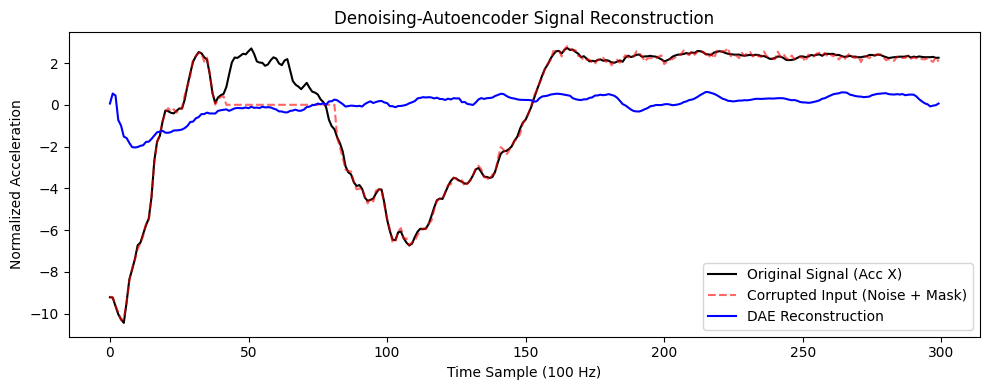

In [5]:
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.figure(figsize=(10, 4))
plt.plot(sample_recon_orig[0, :, 0], label="Original Signal (Acc X)", color="black", linewidth=1.5)
plt.plot(sample_recon_corr[0, :, 0], label="Corrupted Input (Noise + Mask)", color="red", alpha=0.6, linestyle="--")
plt.plot(sample_recon_pred[0, :, 0], label="DAE Reconstruction", color="blue", linewidth=1.5)
plt.title("Denoising-Autoencoder Signal Reconstruction")
plt.xlabel("Time Sample (100 Hz)")
plt.ylabel("Normalized Acceleration")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "plots", "v2_dae_reconstruction.png"), dpi=150)
plt.show()

Evaluating the 3 variants: (1) Scratch, (2) Frozen Encoder, (3) Fine-Tuning across 3 split seeds

In [6]:
def build_classifier(encoder, freeze_encoder=False, lr=1e-3, num_classes=3):
    if freeze_encoder:
        for layer in encoder.layers:
            layer.trainable = False
    else:
        for layer in encoder.layers:
            layer.trainable = True
            
    inp = encoder.input
    emb = encoder.output
    x = layers.Dense(32, activation="relu")(emb)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

split_seeds = [42, 43, 44]
variant_names = ["Scratch (No Pretrain)", "Frozen Pretrained Encoder", "Fine-Tuned Pretrained Encoder"]
variant_sub_probs = {v: [] for v in variant_names}
variant_win_probs = {v: [] for v in variant_names}

for s in split_seeds:
    tf.random.set_seed(s)
    np.random.seed(s)
    
    oof_v = {v: np.zeros((len(y_pads), 3), dtype=np.float32) for v in variant_names}
    
    for fold in range(5):
        tr_idx = splits[f"split_{s}_tr_{fold}"]
        te_idx = splits[f"split_{s}_te_{fold}"]
        
        ch_std = Xd_primary[tr_idx].std(axis=(0, 1))
        ch_std[ch_std == 0] = 1.0
        Xn_tr = (Xd_primary[tr_idx] / ch_std).astype(np.float32)
        Xn_te = (Xd_primary[te_idx] / ch_std).astype(np.float32)
        
        cw = compute_class_weight("balanced", classes=np.unique(y_pads[tr_idx]), y=y_pads[tr_idx])
        cw_dict = dict(enumerate(cw))
        weights_file = os.path.join("..", "results", "models", f"v2_dae_encoder_fold_{fold}.weights.h5")
        
        tf.keras.backend.clear_session()
        enc_scratch, _ = build_dae()
        m_scratch = build_classifier(enc_scratch, freeze_encoder=False, lr=1e-3)
        m_scratch.fit(Xn_tr, y_pads[tr_idx], validation_split=0.15, epochs=12, batch_size=256, class_weight=cw_dict, verbose=0)
        oof_v["Scratch (No Pretrain)"][te_idx] = m_scratch.predict(Xn_te, batch_size=1024, verbose=0)
        
        tf.keras.backend.clear_session()
        enc_frozen, _ = build_dae()
        enc_frozen.load_weights(weights_file)
        m_frozen = build_classifier(enc_frozen, freeze_encoder=True, lr=1e-3)
        m_frozen.fit(Xn_tr, y_pads[tr_idx], validation_split=0.15, epochs=12, batch_size=256, class_weight=cw_dict, verbose=0)
        oof_v["Frozen Pretrained Encoder"][te_idx] = m_frozen.predict(Xn_te, batch_size=1024, verbose=0)
        
        tf.keras.backend.clear_session()
        enc_ft, _ = build_dae()
        enc_ft.load_weights(weights_file)
        m_ft = build_classifier(enc_ft, freeze_encoder=False, lr=3e-4)
        m_ft.fit(Xn_tr, y_pads[tr_idx], validation_split=0.15, epochs=12, batch_size=256, class_weight=cw_dict, verbose=0)
        oof_v["Fine-Tuned Pretrained Encoder"][te_idx] = m_ft.predict(Xn_te, batch_size=1024, verbose=0)
        
    for v in variant_names:
        sub_p = np.array([np.mean(oof_v[v][groups == sub], axis=0) for sub in unique_subs])
        variant_sub_probs[v].append(sub_p)
        variant_win_probs[v].append(oof_v[v])
        f1_s = float(f1_score(sub_true, np.argmax(sub_p, axis=1), average="macro"))
        print(f"Seed {s} -> {v}: Subject Macro-F1 = {f1_s:.4f}")

Seed 42 -> Scratch (No Pretrain): Subject Macro-F1 = 0.5137


Seed 42 -> Frozen Pretrained Encoder: Subject Macro-F1 = 0.4161


Seed 42 -> Fine-Tuned Pretrained Encoder: Subject Macro-F1 = 0.4783


Seed 43 -> Scratch (No Pretrain): Subject Macro-F1 = 0.5169
Seed 43 -> Frozen Pretrained Encoder: Subject Macro-F1 = 0.3847


Seed 43 -> Fine-Tuned Pretrained Encoder: Subject Macro-F1 = 0.4543


Seed 44 -> Scratch (No Pretrain): Subject Macro-F1 = 0.5340
Seed 44 -> Frozen Pretrained Encoder: Subject Macro-F1 = 0.3991


Seed 44 -> Fine-Tuned Pretrained Encoder: Subject Macro-F1 = 0.4286


Evaluating and comparing pretraining variants with bootstrap confidence intervals and AUROCs

In [7]:
pretrain_records = []
for v in variant_names:
    avg_sub_p = np.mean(variant_sub_probs[v], axis=0)
    sub_preds = np.argmax(avg_sub_p, axis=1)
    avg_win_p = np.mean(variant_win_probs[v], axis=0)
    win_preds = np.argmax(avg_win_p, axis=1)
    
    mean_sub_f1 = float(f1_score(sub_true, sub_preds, average="macro"))
    mean_sub_bacc = float(balanced_accuracy_score(sub_true, sub_preds))
    mean_win_f1 = float(f1_score(y_pads, win_preds, average="macro"))
    mean_win_bacc = float(balanced_accuracy_score(y_pads, win_preds))
    
    f1_ci = v2.compute_bootstrap_ci(sub_true, avg_sub_p, lambda yt, p: f1_score(yt, np.argmax(p, axis=1), average="macro"))
    bacc_ci = v2.compute_bootstrap_ci(sub_true, avg_sub_p, lambda yt, p: balanced_accuracy_score(yt, np.argmax(p, axis=1)))
    
    auc_norm = float(roc_auc_score(sub_true == 0, avg_sub_p[:, 0]))
    auc_pd = float(roc_auc_score(sub_true == 1, avg_sub_p[:, 1]))
    auc_et = float(roc_auc_score(sub_true == 2, avg_sub_p[:, 2]))
    auc_macro = float((auc_norm + auc_pd + auc_et) / 3.0)
    
    print(f"\n=== {v} Pooled Results across 3 Split Seeds ===")
    print(f"Pooled Subject Macro-F1: {mean_sub_f1:.4f} [95% Bootstrap CI: {f1_ci[0]:.4f} - {f1_ci[1]:.4f}]")
    print(f"Pooled Subject Balanced Acc: {mean_sub_bacc:.4f} [95% Bootstrap CI: {bacc_ci[0]:.4f} - {bacc_ci[1]:.4f}]")
    print(f"Subject One-vs-Rest AUROC: Normal={auc_norm:.4f}, PD={auc_pd:.4f}, ET={auc_et:.4f}, Macro={auc_macro:.4f}")
    print(f"Window-Level Macro-F1: {mean_win_f1:.4f} | Balanced Acc: {mean_win_bacc:.4f}")
    
    cm = confusion_matrix(sub_true, sub_preds)
    print("Subject Confusion Matrix:")
    print(pd.DataFrame(cm, index=[f"True_{c}" for c in target_names], columns=[f"Pred_{c}" for c in target_names]))
    for i, c in enumerate(target_names):
        rec = float(cm[i, i] / np.sum(cm[i]))
        print(f"Recall for {c}: {rec:.4f}")
        
    pretrain_records.append({
        "Model": v,
        "Sampling_Rate": "100 Hz",
        "Channels": 6,
        "Subject_Macro_F1": mean_sub_f1,
        "Subject_F1_CI_Low": f1_ci[0],
        "Subject_F1_CI_High": f1_ci[1],
        "Subject_Balanced_Acc": mean_sub_bacc,
        "Subject_BAcc_CI_Low": bacc_ci[0],
        "Subject_BAcc_CI_High": bacc_ci[1],
        "AUROC_Normal": auc_norm,
        "AUROC_PD": auc_pd,
        "AUROC_ET": auc_et,
        "AUROC_Macro": auc_macro,
        "Window_Macro_F1": mean_win_f1,
        "Window_Balanced_Acc": mean_win_bacc
    })

os.makedirs(os.path.join("..", "results", "metrics"), exist_ok=True)
df_pre = pd.DataFrame(pretrain_records)
df_pre.to_csv(os.path.join("..", "results", "metrics", "v2_track1_pretrain_finetune.csv"), index=False)
print("\nSaved results to results/metrics/v2_track1_pretrain_finetune.csv successfully")


=== Scratch (No Pretrain) Pooled Results across 3 Split Seeds ===
Pooled Subject Macro-F1: 0.5064 [95% Bootstrap CI: 0.4411 - 0.5645]
Pooled Subject Balanced Acc: 0.5960 [95% Bootstrap CI: 0.5187 - 0.6686]
Subject One-vs-Rest AUROC: Normal=0.8260, PD=0.7017, ET=0.8725, Macro=0.8000
Window-Level Macro-F1: 0.4196 | Balanced Acc: 0.5315
Subject Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    63                    14             2
True_Parkinsons-like           94                   141            33
True_ET-like                    1                    14            13
Recall for Normal: 0.7975
Recall for Parkinsons-like: 0.5261
Recall for ET-like: 0.4643



=== Frozen Pretrained Encoder Pooled Results across 3 Split Seeds ===
Pooled Subject Macro-F1: 0.3740 [95% Bootstrap CI: 0.3202 - 0.4253]
Pooled Subject Balanced Acc: 0.5193 [95% Bootstrap CI: 0.4450 - 0.5892]
Subject One-vs-Rest AUROC: Normal=0.7320, PD=0.5586, ET=0.7736, Macro=0.6880
Window-Level Macro-F1: 0.3411 | Balanced Acc: 0.4678
Subject Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    64                    13             2
True_Parkinsons-like          129                    76            63
True_ET-like                    4                    11            13
Recall for Normal: 0.8101
Recall for Parkinsons-like: 0.2836
Recall for ET-like: 0.4643



=== Fine-Tuned Pretrained Encoder Pooled Results across 3 Split Seeds ===
Pooled Subject Macro-F1: 0.4865 [95% Bootstrap CI: 0.4292 - 0.5453]
Pooled Subject Balanced Acc: 0.6299 [95% Bootstrap CI: 0.5560 - 0.6984]
Subject One-vs-Rest AUROC: Normal=0.7788, PD=0.6448, ET=0.8662, Macro=0.7632
Window-Level Macro-F1: 0.3737 | Balanced Acc: 0.5174
Subject Confusion Matrix:
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    64                    11             4
True_Parkinsons-like          101                   117            50
True_ET-like                    2                     8            18
Recall for Normal: 0.8101
Recall for Parkinsons-like: 0.4366
Recall for ET-like: 0.6429

Saved results to results/metrics/v2_track1_pretrain_finetune.csv successfully
